----CLEAN DATASET & EXTRACT LABELS----

In [ ]:
import pandas as pd

# Load the new dataset
df = pd.read_excel('/content/phishing_nlp_dataset.xlsx')

print("Original Shape:", df.shape)

# Make a copy of Corpus
df['raw_text'] = df['Corpus'].astype(str)

# Extract label from the end of the text
df['label_extracted'] = df['raw_text'].str.extract(
    r'\t([^\t]+)$'
)[0]

# Remove the tab + label from the text
df['text'] = df['raw_text'].str.replace(
    r'\t[^\t]+$',
    '',
    regex=True
).str.strip()

# Display results
print("\nExtracted Labels:")
print(df['label_extracted'].value_counts(dropna=False))

print("\nSample Cleaned Records:")
display(
    df[['text', 'label_extracted']].head(10)
)

Original Shape: (624, 2)

Extracted Labels:
label_extracted
NOT-Malicious General Class    171
Phishing                       114
Scareware                      100
Baiting                         80
Malware                         78
Pretexting                      78
NaN                              3
Name: count, dtype: int64

Sample Cleaned Records:


,text,label_extracted
0,"You have (1) package waiting, ready for delive...",Phishing
1,We were unable to deliver your package as ther...,Phishing
2,We are here to inform you that we need address...,Phishing
3,You have (1) message from us. Click below to o...,Phishing
4,You have (1) package awaiting delivery. Use yo...,Phishing
5,You have (1) package awaiting delivery. Use yo...,Phishing
6,Your Netflix account has been used to share yo...,Phishing
7,Your Netflix account has been used to share yo...,Phishing
8,Your iCloud account has been used to store ill...,Phishing
9,Your Microsoft account has been used to buy so...,Phishing


In [ ]:
# Verifying Class
print("Unique Labels:")
print(df['label_extracted'].unique())

print("\nNumber of Unique Classes:")
print(df['label_extracted'].nunique())

print("\nClass Distribution:")
print(df['label_extracted'].value_counts(dropna=False))

print("\nMissing Labels:")
print(df['label_extracted'].isna().sum())

Unique Labels:
['Phishing' 'Scareware' 'Malware' 'Baiting' 'Pretexting'
 'NOT-Malicious General Class' nan]

Number of Unique Classes:
6

Class Distribution:
label_extracted
NOT-Malicious General Class    171
Phishing                       114
Scareware                      100
Baiting                         80
Malware                         78
Pretexting                      78
NaN                              3
Name: count, dtype: int64

Missing Labels:
3


In [ ]:
# Checking duplicates
# ============================================
# STEP 12C: DUPLICATE CHECK
# ============================================

print("Duplicate Texts:", df['text'].duplicated().sum())

print(
    "\nDuplicate Text + Label:",
    df[['text', 'label_extracted']].duplicated().sum()
)

Duplicate Texts: 15

Duplicate Text + Label: 9


In [ ]:
# ============================================
# STEP 13A: CREATE FINAL CLEAN DATASET
# ============================================

# Keep only text and extracted label
df_final = df[['text', 'label_extracted']].copy()

# Rename label column
df_final.rename(
    columns={'label_extracted': 'label'},
    inplace=True
)

# Remove missing labels
df_final.dropna(subset=['text', 'label'], inplace=True)

# Remove empty text
df_final = df_final[
    df_final['text'].str.strip() != ''
]

# Remove exact duplicate text-label pairs
df_final.drop_duplicates(
    subset=['text', 'label'],
    inplace=True
)

# Reset index
df_final.reset_index(drop=True, inplace=True)

print("Final Dataset Shape:", df_final.shape)

print("\nColumns:")
print(df_final.columns.tolist())

print("\nMissing Values:")
print(df_final.isnull().sum())

print("\nDuplicate Records:")
print(df_final.duplicated().sum())

print("\nFinal Class Distribution:")
print(df_final['label'].value_counts())

print("\nFinal Dataset:")
display(df_final.head(10))

Final Dataset Shape: (612, 2)

Columns:
['text', 'label']

Missing Values:
text     0
label    0
dtype: int64

Duplicate Records:
0

Final Class Distribution:
label
NOT-Malicious General Class    171
Phishing                       113
Scareware                      100
Baiting                         80
Malware                         77
Pretexting                      71
Name: count, dtype: int64

Final Dataset:


,text,label
0,"You have (1) package waiting, ready for delive...",Phishing
1,We were unable to deliver your package as ther...,Phishing
2,We are here to inform you that we need address...,Phishing
3,You have (1) message from us. Click below to o...,Phishing
4,You have (1) package awaiting delivery. Use yo...,Phishing
5,You have (1) package awaiting delivery. Use yo...,Phishing
6,Your Netflix account has been used to share yo...,Phishing
7,Your Netflix account has been used to share yo...,Phishing
8,Your iCloud account has been used to store ill...,Phishing
9,Your Microsoft account has been used to buy so...,Phishing


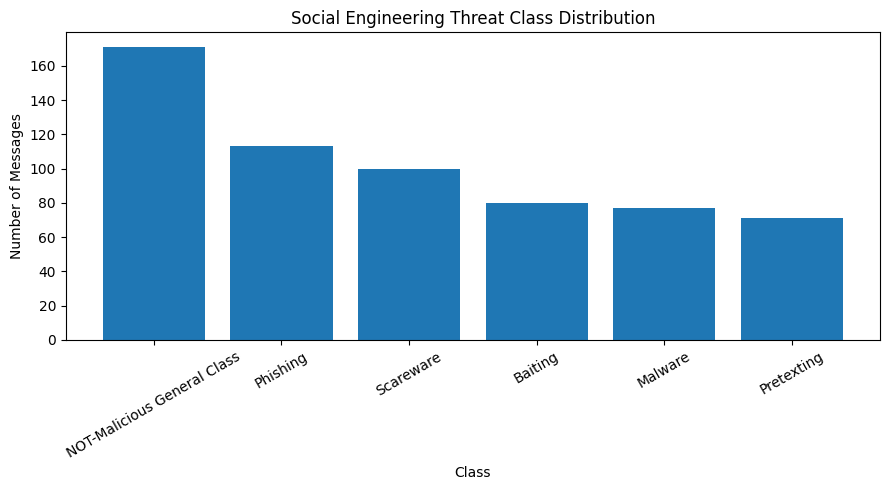

In [ ]:
# ============================================
# STEP 13B: CLASS DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt

class_counts = df_final['label'].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.title("Social Engineering Threat Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Messages")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# STEP 14A: DATASET INFORMATION
# ============================================

print("Dataset Shape:", df_final.shape)

print("\nDataset Information:")
df_final.info()

print("\nMissing Values:")
print(df_final.isnull().sum())

print("\nDuplicate Records:")
print(df_final.duplicated().sum())

Dataset Shape: (612, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    612 non-null    object
 1   label   612 non-null    object
dtypes: object(2)
memory usage: 9.7+ KB

Missing Values:
text     0
label    0
dtype: int64

Duplicate Records:
0


In [ ]:
# ============================================
# STEP 14E: SAMPLE FROM EACH CLASS
# ============================================

for label in sorted(df_final['label'].unique()):

    print("\n" + "=" * 70)
    print("CLASS:", label)
    print("=" * 70)

    samples = df_final[
        df_final['label'] == label
    ].sample(
        min(3, len(df_final[df_final['label'] == label])),
        random_state=42
    )

    for i, text in enumerate(samples['text'], 1):
        print(f"\nSample {i}:")
        print(text[:500])


CLASS: Baiting

Sample 1:
We send you an invitation to an exclusive raffle attached. Please download and use the invitation to enter the draw and win a prize.

Sample 2:
We send you an exclusive discount code as an attachment. Please download and use the code to get 50% off your next purchase.

Sample 3:
We send you an exclusive offer for a free membership as an attachment. Please download and use the offer to get a free subscription to our weather forecast service.

CLASS: Malware

Sample 1:
We send you an invitation to an event as an attachment. Please open the file to view details and confirm participation.

Sample 2:
We send you a presentation attached. Please download the file to view the contents.

Sample 3:
We send you a photo as an attachment. Please download the image to view the content.

CLASS: NOT-Malicious General Class

Sample 1:
I decided to learn to play the guitar. It's a challenge, but I really enjoy it.

Sample 2:
I wanted to update you on the latest news, you know 

In [ ]:
# ============================================
# STEP 15A: NLP TEXT PREPROCESSING
# ============================================

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Initialize tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    # Convert to string and lowercase
    text = str(text).lower()

    # Replace URLs with URL token
    text = re.sub(
        r'https?://\S+|www\.\S+',
        ' URL ',
        text
    )

    # Remove HTML tags
    text = re.sub(
        r'<.*?>',
        ' ',
        text
    )

    # Keep alphabets and spaces
    text = re.sub(
        r'[^a-zA-Z\s]',
        ' ',
        text
    )

    # Remove extra spaces
    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()

    # Tokenization
    words = text.split()

    # Stopword removal + lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


# Apply preprocessing
df_final['clean_text'] = df_final['text'].apply(
    preprocess_text
)

print("Preprocessing completed successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Preprocessing completed successfully!


In [ ]:
# ============================================
# STEP 15B: ORIGINAL VS CLEANED TEXT
# ============================================

display(
    df_final[
        ['text', 'clean_text', 'label']
    ].sample(
        10,
        random_state=42
    )
)

,text,clean_text,label
81,Your account has been used to make fraudulent ...,account used make fraudulent transaction pleas...,Scareware
218,We send you an invitation to an exclusive raff...,send invitation exclusive raffle attached plea...,Baiting
55,Your Instagram account has been hacked. Click ...,instagram account hacked click change password,Phishing
600,Click this link to see the latest news.,click link see latest news,Malware
264,I'm a customer service representative for your...,customer service representative loyalty card c...,Pretexting
155,We send you a note as an attachment. Please do...,send note attachment please download file view...,Malware
483,Your account has been selected for a security ...,account selected security review provide crede...,Baiting
321,Unfortunately this evening is not possible. Ca...,unfortunately evening possible hear next day a...,NOT-Malicious General Class
582,Our research team is working on an ambitious p...,research team working ambitious project lookin...,NOT-Malicious General Class
291,We are writing to you from PayPal customer ser...,writing paypal customer service need email add...,Pretexting


In [ ]:
# ============================================
# STEP 16A: PREPARE FEATURES AND TARGET
# ============================================

from sklearn.model_selection import train_test_split

# Input feature
X = df_final['clean_text']

# Target labels
y = df_final['label']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nClass Distribution:")
print(y.value_counts())

Feature Shape: (612,)
Target Shape: (612,)

Class Distribution:
label
NOT-Malicious General Class    171
Phishing                       113
Scareware                      100
Baiting                         80
Malware                         77
Pretexting                      71
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 16B: TRAIN-TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Samples: 489
Testing Samples: 123

Training Class Distribution:
label
NOT-Malicious General Class    137
Phishing                        90
Scareware                       80
Baiting                         64
Malware                         61
Pretexting                      57
Name: count, dtype: int64

Testing Class Distribution:
label
NOT-Malicious General Class    34
Phishing                       23
Scareware                      20
Baiting                        16
Malware                        16
Pretexting                     14
Name: count, dtype: int64


In [ ]:
# ============================================
# STEP 16C: TF-IDF FEATURE EXTRACTION
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Training Shape:", X_train_tfidf.shape)
print("TF-IDF Testing Shape:", X_test_tfidf.shape)

TF-IDF Training Shape: (489, 1924)
TF-IDF Testing Shape: (123, 1924)


In [ ]:
# ============================================
# STEP 16D: INSPECT TF-IDF FEATURES
# ============================================

feature_names = tfidf.get_feature_names_out()

print("Total TF-IDF Features:", len(feature_names))

print("\nFirst 50 Features:")
print(feature_names[:50])

Total TF-IDF Features: 1924

First 50 Features:
['ability' 'ability handle' 'able' 'abroad' 'abroad assist' 'accept'
 'access' 'access content' 'access fraudulent' 'accordingly'
 'accordingly soon' 'account' 'account blocked' 'account compromised'
 'account disabled' 'account family' 'account hacked' 'account number'
 'account provide' 'account reset' 'account selected' 'account suspended'
 'account used' 'accumulated' 'accumulated royalty' 'acquired'
 'acquired late' 'act' 'activity' 'activity account' 'activity click'
 'address' 'address hope' 'address password' 'adventure' 'advice'
 'advised' 'advised look' 'adware' 'adware please' 'age' 'ago' 'ago await'
 'agriculture' 'agriculture major' 'aide' 'air' 'airport' 'alive'
 'allowed']


In [ ]:
# ============================================
# STEP 16E: TF-IDF MATRIX INFORMATION
# ============================================

print("Training Matrix")
print("----------------")
print("Rows:", X_train_tfidf.shape[0])
print("Columns:", X_train_tfidf.shape[1])
print("Non-zero Values:", X_train_tfidf.nnz)

print("\nTesting Matrix")
print("----------------")
print("Rows:", X_test_tfidf.shape[0])
print("Columns:", X_test_tfidf.shape[1])
print("Non-zero Values:", X_test_tfidf.nnz)

Training Matrix
----------------
Rows: 489
Columns: 1924
Non-zero Values: 9914

Testing Matrix
----------------
Rows: 123
Columns: 1924
Non-zero Values: 1610


In [ ]:
# ============================================
# STEP 17A: DEFINE MULTICLASS ML MODELS
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

print("Models:")
for name in models:
    print("-", name)

Models:
- Logistic Regression
- Naive Bayes
- Linear SVM
- Random Forest


In [ ]:
# ============================================
# STEP 17B: TRAIN MULTICLASS MODELS
# ============================================

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(
        X_train_tfidf,
        y_train
    )

    trained_models[name] = model

print("\nAll models trained successfully!")

Training Logistic Regression...
Training Naive Bayes...
Training Linear SVM...
Training Random Forest...

All models trained successfully!


In [ ]:
# ============================================
# STEP 17C: GENERATE PREDICTIONS
# ============================================

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

    print(f"{name}: Predictions generated")

print("\nPrediction process completed!")

Logistic Regression: Predictions generated
Naive Bayes: Predictions generated
Linear SVM: Predictions generated
Random Forest: Predictions generated

Prediction process completed!


In [ ]:
# ============================================
# STEP 17D: MULTICLASS MODEL COMPARISON
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

# Sort according to F1 Score
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.886179,0.885176,0.886179,0.883580
1,Naive Bayes,0.878049,0.881550,0.878049,0.877107
2,Logistic Regression,0.869919,0.884427,0.869919,0.869888
3,Random Forest,0.869919,0.873245,0.869919,0.867398


In [ ]:
# ============================================
# STEP 19A: FINAL PREDICTION FUNCTION
# ============================================

# Get best model from model comparison
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)


def predict_message(message):

    # Preprocess message
    cleaned_message = preprocess_text(message)

    # Convert to TF-IDF
    message_tfidf = tfidf.transform([cleaned_message])

    # Prediction
    prediction = best_model.predict(message_tfidf)[0]

    return prediction

Best Model: Linear SVM


In [ ]:
# ============================================
# STEP 19B: TEST PREDICTIONS
# ============================================

test_messages = [
    "Your bank account has been suspended. Verify your password immediately.",
    "Congratulations! You have won a free prize. Click the link to claim it.",
    "Please find attached the report for tomorrow's meeting."
]

for message in test_messages:

    prediction = predict_message(message)

    print("=" * 70)
    print("Message:")
    print(message)

    print("\nPredicted Class:")
    print(prediction)

Message:
Your bank account has been suspended. Verify your password immediately.

Predicted Class:
Phishing
Message:
Congratulations! You have won a free prize. Click the link to claim it.

Predicted Class:
Phishing
Message:
Please find attached the report for tomorrow's meeting.

Predicted Class:
NOT-Malicious General Class


In [ ]:
# ============================================
# STEP 20A: SAVE MODEL AND TF-IDF
# ============================================

import joblib

# Save trained model
joblib.dump(best_model, "best_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!
